# Bay Area Displacement Early-Warning — Initial EDA

**Data:** Urban Displacement Project (UDP) Bay Area full typology CSV, plus optional tract-level indicators.  
**Status:** Run after downloading the original CSV; no counts or relationships are assumed in advance.

Download from [UDP's public datasets](https://github.com/urban-displacement/displacement-typologies/tree/main/data/outputs/typologies) and place Bay Area CSV(s) in `data/`. The notebook will ask you to select the correct file if more than one is found.

**Research question:** Which tract characteristics are associated with UDP classifications, and which indicators could support a *future* displacement early-warning model?

**Important:** UDP classifications are historical and are **not a measured future-displacement target**. Predictive modeling needs an independently measured longitudinal outcome.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
DATA_DIR = Path('data')
files = sorted(DATA_DIR.rglob('*.csv')) if DATA_DIR.exists() else []
print('Available CSV files:')
for idx, p in enumerate(files): print(idx, p)
assert files, 'Download UDP Bay Area typology CSV and put it in a data/ folder first.'
FILE_INDEX = 0  # Set to the index of the correct Bay Area CSV above
path = files[FILE_INDEX]
df = pd.read_csv(path, low_memory=False, dtype={'GEOID':'string','geoid':'string','GEOID10':'string'})
print('Loaded:', path, '| shape:', df.shape)
display(df.head())

Available CSV files:
0 data/SanFrancisco_typology_output.csv
Loaded: data/SanFrancisco_typology_output.csv | shape: (2109, 306)


,Unnamed: 0,pop_18,white_18,hh_18,hinc_18,mhval_18,mhval_18_se,mrent_18,mrent_18_se,total_25_18,...,BE,SMMI,ARG,EOG,OD,OD_loss,LISD,double_counted,typology,typ_cat
0,0,2772.0,1388.0,1108.0,55125.0,640600.0,36856.0,1185.0,99.0,2014.0,...,0.0,0.0,0.0,0.0,0,0.0,1,1.0,1.0,['LISD']
1,1,4127.0,2874.0,1550.0,100202.0,718900.0,47042.0,1829.0,132.0,2919.0,...,0.0,1.0,0.0,0.0,0,0.0,0,1.0,6.0,['SMMI']
2,2,722.0,396.0,37.0,6953.0,-666666666.0,-222222222.0,394.0,362.0,699.0,...,0.0,0.0,1.0,0.0,0,0.0,0,1.0,3.0,['ARG']
3,3,5070.0,3335.0,2045.0,40733.0,321000.0,38985.0,910.0,131.0,3501.0,...,0.0,0.0,0.0,0.0,0,0.0,1,1.0,1.0,['LISD']
4,4,3338.0,1900.0,1628.0,33194.0,328400.0,35481.0,952.0,47.0,2257.0,...,0.0,0.0,0.0,0.0,1,1.0,0,1.0,2.0,['OD']


## 1. Scope and typology counts
The UDP file covers 13 counties (it adds Sacramento, San Joaquin, Yolo and Santa Cruz). Everything below keeps the 9 Bay Area counties and tracts with at least 500 people in 2000.

,tracts,population_2018,share_of_tracts
typology_name,,,
Stable moderate / mixed income,575,2890895.0,0.371
Low-income / susceptible to displacement,248,1219119.0,0.160
At risk of becoming exclusive,247,1288603.0,0.159
Stable / advanced exclusive,227,1113713.0,0.146
Becoming exclusive,78,338928.0,0.050
At risk of gentrification,58,240097.0,0.037
Advanced gentrification,47,204350.0,0.030
Advanced gentrification + becoming exclusive,25,96409.0,0.016
Ongoing displacement,24,96529.0,0.015


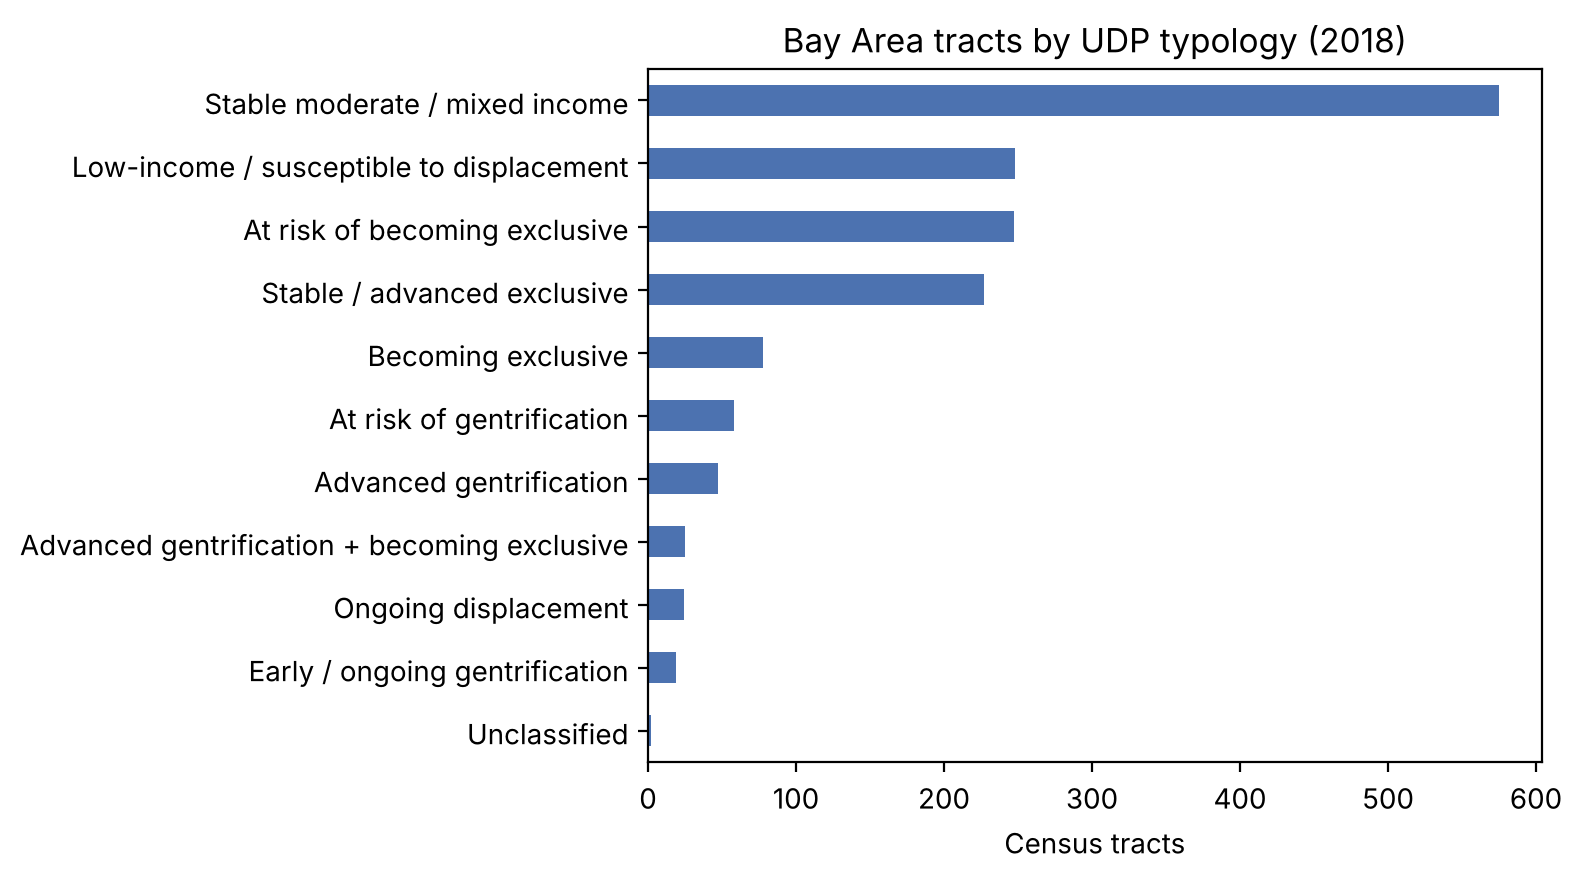

In [2]:
df['GEOID']=df['GEOID'].str.zfill(11)
bay={'001':'Alameda','013':'Contra Costa','041':'Marin','055':'Napa','075':'San Francisco','081':'San Mateo','085':'Santa Clara','095':'Solano','097':'Sonoma'}
names={'LISD':'Low-income / susceptible to displacement','OD':'Ongoing displacement','ARG':'At risk of gentrification','EOG':'Early / ongoing gentrification','AdvG':'Advanced gentrification','SMMI':'Stable moderate / mixed income','ARE':'At risk of becoming exclusive','BE':'Becoming exclusive','SAE':'Stable / advanced exclusive','AdvG, BE':'Advanced gentrification + becoming exclusive','Unclassified':'Unclassified'}
d=df[df['GEOID'].str[2:5].isin(bay)&(df['pop00flag']==1)].replace([np.inf,-np.inf],np.nan).copy()
d['county']=d['GEOID'].str[2:5].map(bay)
d['typ']=d['typ_cat'].str.replace(r"[\[\]']",'',regex=True).replace('','Unclassified')
d['typology_name']=d['typ'].map(names)
t=d.groupby('typology_name').agg(tracts=('GEOID','size'),population_2018=('pop_18','sum')).sort_values('tracts')
t['share_of_tracts']=(t.tracts/t.tracts.sum()).round(3)
display(t.sort_values('tracts',ascending=False))
ax=t.tracts.plot.barh(figsize=(8,4.5),color='#4c72b0'); ax.set_xlabel('Census tracts'); ax.set_ylabel(''); ax.set_title('Bay Area tracts by UDP typology (2018)'); plt.tight_layout(); plt.show()

## 2. Tract profile by typology (medians)

In [3]:
cols={'real_hinc_18':'Median household income','per_all_li_18':'Low-income household share','per_rent_18':'Renter share','per_nonwhite_18':'Non-white share','per_col_18':'College-educated share','real_mrent_18':'Median rent','pctch_real_mrent_12_18':'Real rent change 2012-18','ch_all_li_count_00_18':'Change in low-income households 2000-18'}
display(d.groupby('typology_name')[list(cols)].median().rename(columns=cols).sort_values('Median household income').round(2))

,Median household income,Low-income household share,Renter share,Non-white share,College-educated share,Median rent,Real rent change 2012-18,Change in low-income households 2000-18
typology_name,,,,,,,,
At risk of gentrification,44350.5,0.71,0.69,0.87,0.17,1163.5,0.09,117.33
Ongoing displacement,52129.5,0.66,0.89,0.68,0.40,1293.0,0.14,-109.29
Low-income / susceptible to displacement,59195.5,0.59,0.61,0.77,0.21,1467.0,0.11,251.06
Early / ongoing gentrification,64808.0,0.55,0.66,0.68,0.41,1460.0,0.21,-31.10
Advanced gentrification + becoming exclusive,98482.0,0.38,0.61,0.52,0.55,1688.0,0.17,-82.63
Advanced gentrification,98724.0,0.37,0.59,0.62,0.50,1842.0,0.17,48.54
At risk of becoming exclusive,102944.0,0.34,0.32,0.51,0.44,1874.0,0.08,169.99
Stable moderate / mixed income,105457.0,0.33,0.36,0.60,0.47,2059.0,0.24,129.72
Becoming exclusive,113752.0,0.29,0.53,0.49,0.63,1981.0,0.24,-58.75


## 3. Typology by county, and loss of low-income households 2000-2018
`lostli_18` = 1 when a tract had fewer low-income households in 2018 than in 2000.

typ,ARE,ARG,AdvG,"AdvG, BE",BE,EOG,LISD,OD,SAE,SMMI,Unclassified
county,,,,,,,,,,,
Alameda,28,29,14,14,22,12,61,7,42,125,0
Contra Costa,31,15,0,0,7,0,34,1,31,75,0
Marin,22,0,1,0,1,0,4,0,13,11,0
Napa,0,1,2,2,1,0,10,2,1,20,1
San Francisco,24,2,25,7,22,4,24,9,16,58,0
San Mateo,21,1,1,1,12,0,15,0,46,59,0
Santa Clara,69,0,3,1,10,2,37,3,77,168,0
Solano,28,10,0,0,0,0,27,1,1,26,1
Sonoma,24,0,1,0,3,1,36,1,0,33,0


,tracts,lost,share
county,,,
Solano,94,7,0.074
Sonoma,99,8,0.081
Santa Clara,370,36,0.097
Contra Costa,194,19,0.098
Marin,52,8,0.154
Napa,40,8,0.200
San Mateo,156,33,0.212
Alameda,354,93,0.263
San Francisco,191,80,0.419


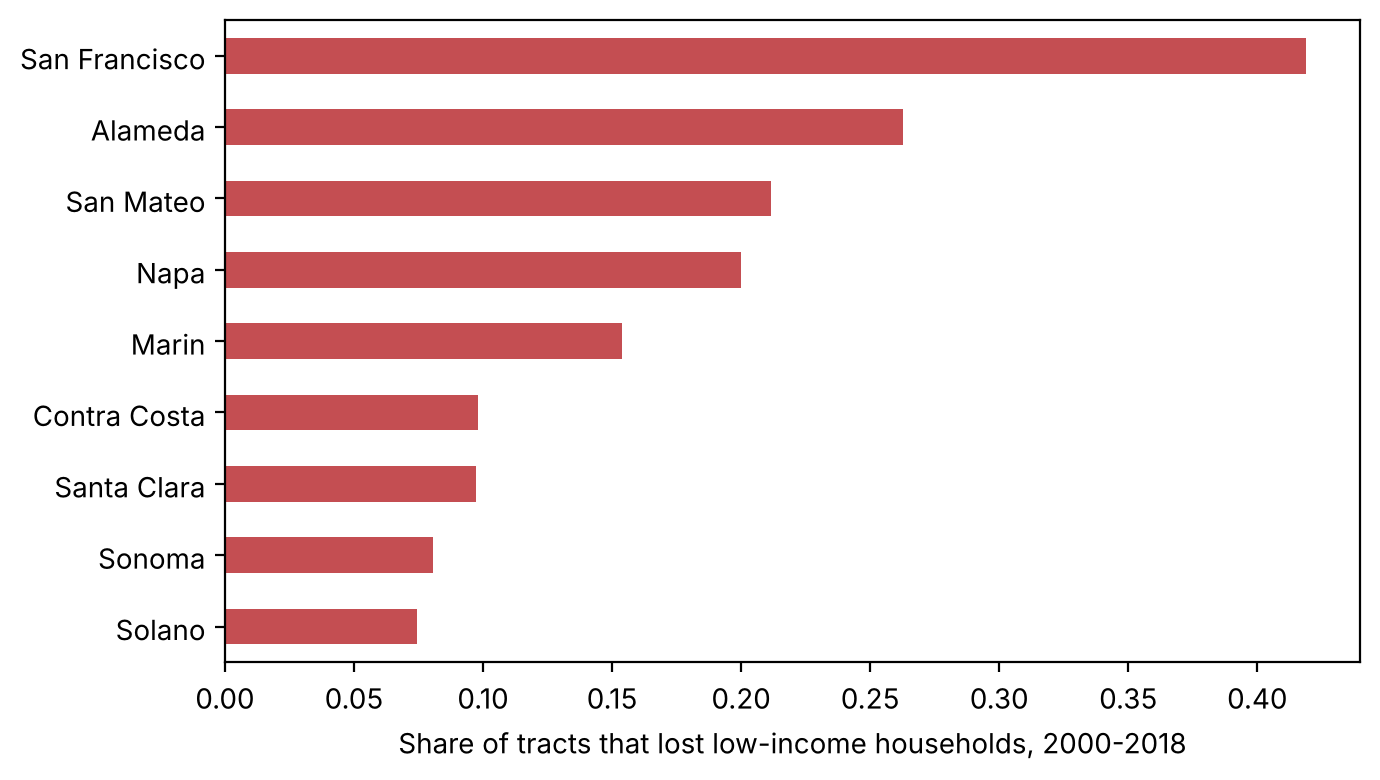

In [4]:
display(pd.crosstab(d['county'],d['typ']))
c=d.groupby('county')['lostli_18'].agg(tracts='size',lost='sum',share='mean').sort_values('share'); display(c.round(3))
ax=c.share.plot.barh(figsize=(7,4),color='#c44e52'); ax.set_xlabel('Share of tracts that lost low-income households, 2000-2018'); ax.set_ylabel(''); plt.tight_layout(); plt.show()

## 4. Backtest: can year-2000 data predict loss of low-income households by 2018?
Features use only 1990 and 2000 values. Each county is held out in turn (grouped 5-fold), so scores are for counties the model has not seen. Baselines are UDP's own year-2000 rule flags. This is a historical test of the early-warning idea, not a forecast.

In [5]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score
X=['per_all_li_00','per_nonwhite_00','per_rent_00','per_col_00','real_mrent_00','real_mhval_00','real_hinc_00','per_all_li_90','per_nonwhite_90','per_rent_90','per_col_90','pctch_real_mhval_90_00','pctch_real_mrent_90_00','pctch_real_hinc_90_00','ch_per_col_90_00','ch_all_li_count_90_00','all_li_count_00','rail','lostli_00']
y=d['lostli_18'].values; g=d['county'].values
models={'Logistic regression':make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LogisticRegression(max_iter=2000,class_weight='balanced')),
        'Gradient boosting':HistGradientBoostingClassifier(max_depth=3,learning_rate=0.05,max_iter=200,random_state=0)}
rows=[]; pred={}
for n,m in models.items():
    pred[n]=cross_val_predict(m,d[X],y,cv=GroupKFold(5),groups=g,method='predict_proba')[:,1]
    rows.append({'model':n,'AUC':roc_auc_score(y,pred[n]),'average precision':average_precision_score(y,pred[n])})
for b,lab in [('vul_gent_00','UDP rule: vulnerable to gentrification in 2000'),('lostli_00','Rule: lost low-income households 1990-2000')]:
    rows.append({'model':lab,'AUC':roc_auc_score(y,d[b]),'average precision':average_precision_score(y,d[b])})
print('Base rate:',round(y.mean(),3)); display(pd.DataFrame(rows).round(3))

Base rate: 0.188


,model,AUC,average precision
0,Logistic regression,0.776,0.457
1,Gradient boosting,0.751,0.392
2,UDP rule: vulnerable to gentrification in 2000,0.542,0.205
3,Rule: lost low-income households 1990-2000,0.483,0.184


## 5. Error check across subgroups
Flag the same number of tracts as actually lost low-income households, then compare recall and precision by group.

In [6]:
p=pred['Logistic regression']; k=int(y.sum()); d['p']=p; d['flag']=(p>=np.sort(p)[-k]).astype(int)
d['Income tier (2000)']=pd.qcut(d['real_hinc_00'],3,labels=['low','middle','high'])
d['Race (2000)']=np.where(d['per_nonwhite_00']>=.5,'majority non-white','majority white')
d['Tenure (2000)']=np.where(d['per_rent_00']>=.5,'majority renter','majority owner')
for s in ['Income tier (2000)','Race (2000)','Tenure (2000)','county']:
    r=d.groupby(s,observed=True).apply(lambda x: pd.Series({'tracts':len(x),'actual loss rate':x['lostli_18'].mean(),'recall':recall_score(x['lostli_18'],x['flag'],zero_division=0),'precision':precision_score(x['lostli_18'],x['flag'],zero_division=0)}))
    display(r.round(2))

,tracts,actual loss rate,recall,precision
Income tier (2000),,,,
low,517.0,0.23,0.62,0.49
middle,517.0,0.20,0.40,0.53
high,516.0,0.14,0.35,0.38


,tracts,actual loss rate,recall,precision
Race (2000),,,,
majority non-white,696.0,0.17,0.47,0.47
majority white,854.0,0.20,0.48,0.48


,tracts,actual loss rate,recall,precision
Tenure (2000),,,,
majority owner,1028.0,0.12,0.21,0.33
majority renter,522.0,0.33,0.66,0.53


,tracts,actual loss rate,recall,precision
county,,,,
Alameda,354.0,0.26,0.48,0.58
Contra Costa,194.0,0.10,0.26,0.28
Marin,52.0,0.15,0.75,0.24
Napa,40.0,0.20,0.00,0.00
San Francisco,191.0,0.42,0.76,0.60
San Mateo,156.0,0.21,0.21,0.64
Santa Clara,370.0,0.10,0.28,0.27
Solano,94.0,0.07,0.14,0.17
Sonoma,99.0,0.08,0.50,0.25
